<a href="https://colab.research.google.com/github/MKSakthi/L02-hedonic-pricing/blob/main/Team_2_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Meena Sakthi, AI Yongqi, Abdul-Salam Gidado, Justin Diamond

**Date:** 11/09/26

Original dataset shape: (16814, 19)
Missing categorical values:
hvac_description        7
exterior                1
interior                7
roof_cover              8
waterfront_type     16261
view_quality        15895
utility_sewer           0
dtype: int64
Rows in multi-building sales: 386
Multi-building rows among the 10 highest prices: 6
Number of duplicate rows: 38
Number of suspicious observations removed: 103
Cleaned dataset shape: (16287, 19)
Remaining missing values: 0
count      16287.0
mean      456918.0
std       200996.0
min        25000.0
25%       349000.0
50%       415500.0
75%       520000.0
max      3500000.0
Name: sale_price, dtype: float64


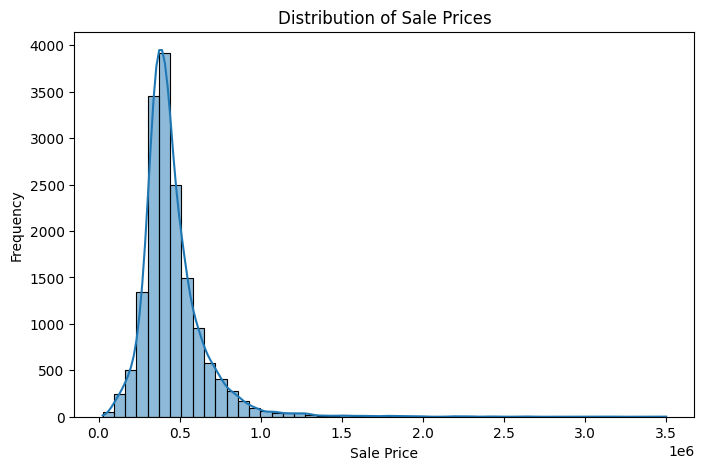

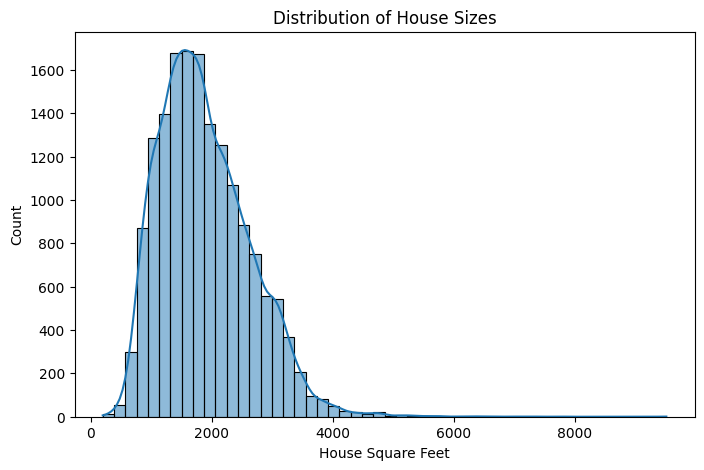

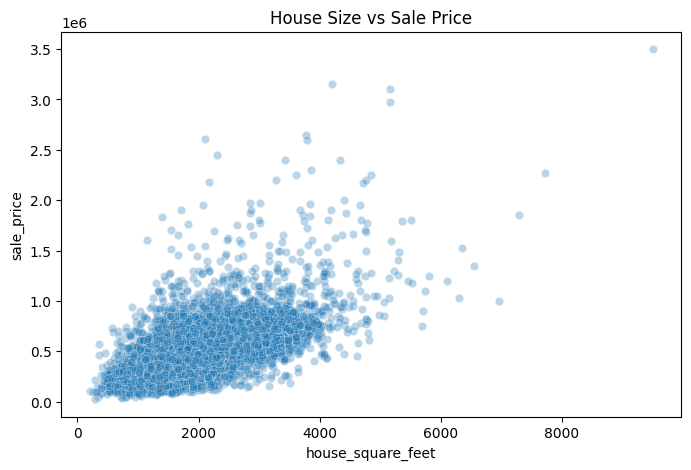

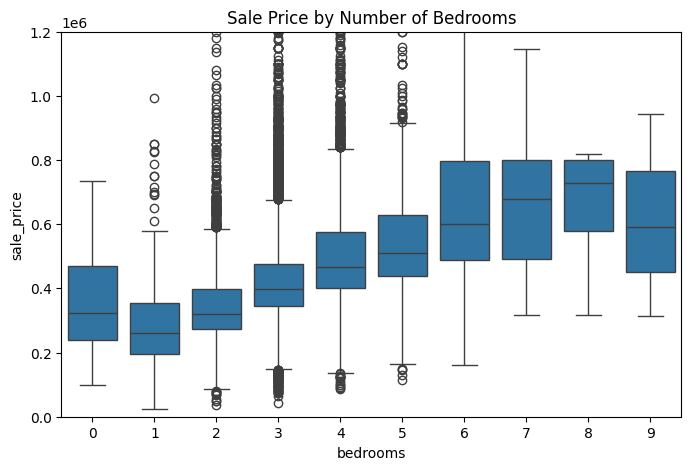

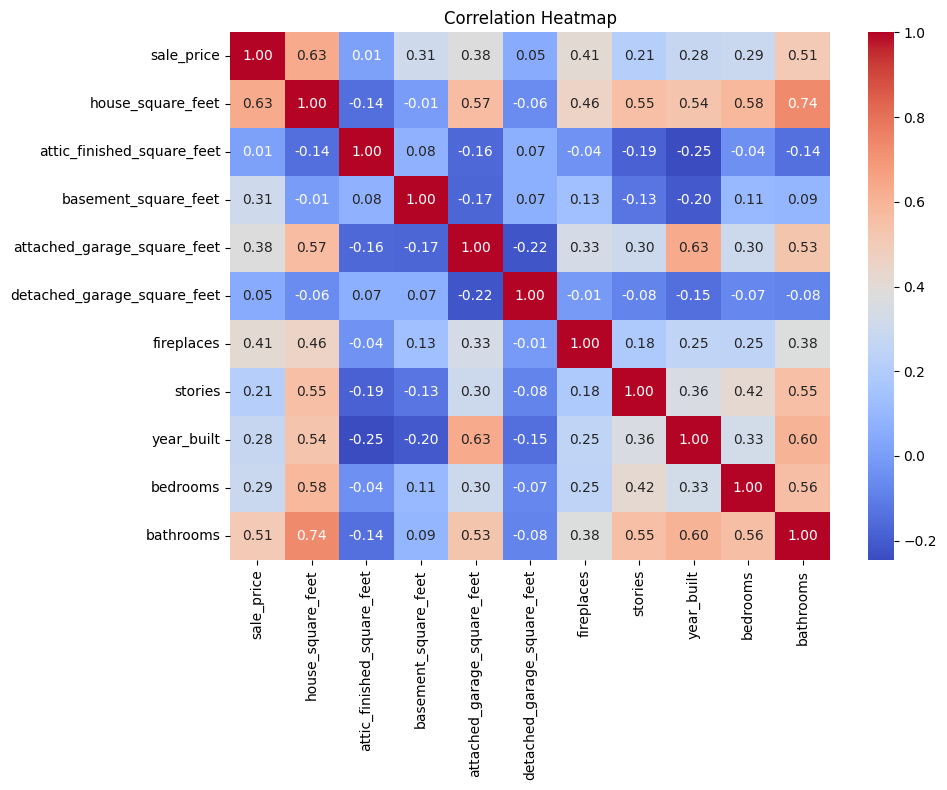

In [ ]:
# Question 1 - Cleaning and EDA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/L02-hedonic-pricing/data/pierce_county_house_sales.csv")

# Cleaning the data
df["sale_date"] = pd.to_datetime(df["sale_date"])

categoricalcols = [
"hvac_description",
"exterior",
"interior",
"roof_cover",
"waterfront_type",
"view_quality",
"utility_sewer"
]

print("Original dataset shape:", df.shape)
print("Missing categorical values:")
print(df[categoricalcols].isnull().sum())

# A sale of several buildings shows up as back-to-back rows with the same date and price,
# so every building in it carries the price of the whole sale
same_sale = (df["sale_date"] == df["sale_date"].shift()) & (df["sale_price"] == df["sale_price"].shift())
multi_building = same_sale | same_sale.shift(-1, fill_value=False)
print("Rows in multi-building sales:", multi_building.sum())
print("Multi-building rows among the 10 highest prices:", multi_building[df["sale_price"].nlargest(10).index].sum())
print("Number of duplicate rows:", df.loc[~multi_building].duplicated().sum())

# Remove multi-building sales and duplicate rows
df_clean = df.loc[~multi_building].drop_duplicates().copy()

# Remove suspicious observations
price_per_sqft = df_clean["sale_price"] / df_clean["house_square_feet"]
suspicious = (
    (df_clean["sale_price"] < 10000)
    | (df_clean["house_square_feet"] < 200)
    | (df_clean["year_built"] > df_clean["sale_date"].dt.year)
    | (price_per_sqft < 50)
    | (price_per_sqft > 2000)
    | (df_clean["bedrooms"] > 20)
)

print("Number of suspicious observations removed:", suspicious.sum())
df_clean = df_clean.loc[~suspicious].copy()

# A blank waterfront type or view means the house has none
df_clean["waterfront_type"] = df_clean["waterfront_type"].fillna("None")
df_clean["view_quality"] = df_clean["view_quality"].fillna("None")
df_clean["hvac_description"] = df_clean["hvac_description"].replace("Floor Wall Furnace", "Floor/Wall Furnace")

# Fill the few remaining missing categorical values
for col in categoricalcols:
    df_clean[col] = df_clean[col].fillna("Not recorded")

# Final cleaning checks
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())
print(df_clean["sale_price"].describe().round(0))

# Distribution of sale prices
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["sale_price"], bins=50, kde=True)
plt.title("Distribution of Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

# Distribution of house sizes
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["house_square_feet"], bins=50, kde=True)
plt.title("Distribution of House Sizes")
plt.xlabel("House Square Feet")
plt.show()

# House size vs sale price
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean,
    x="house_square_feet",
    y="sale_price",
    alpha=0.3
)
plt.title("House Size vs Sale Price")
plt.show()

# Bedrooms vs sale price
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="bedrooms", y="sale_price")
plt.ylim(0, df_clean["sale_price"].quantile(0.99))
plt.title("Sale Price by Number of Bedrooms")
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    df_clean.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

The raw data have 16,814 sales. Most of the missing values are in waterfront_type and view_quality, and a blank there just means the house has no waterfront or view, so we fill them with None. The few blanks in the other building descriptions become Not recorded, so no missing values remain.

Some rows are not a normal sale of one house. When a sale includes several buildings, each building gets its own row with the full sale price, one right after another. We drop these 386 rows, which include 6 of the 10 highest prices, along with 38 duplicate rows. We also drop 103 suspicious rows, such as sales below \$50 or above \$2,000 per square foot, houses built after the year they sold, and a house listed with more than 20 bedrooms. That leaves 16,287 sales.

Sale prices are right-skewed. The median is \$415,500, the mean is higher at \$456,918, and the most expensive sale is \$3,500,000. Price rises with house size, and the spread gets wider for bigger houses. In the heatmap, house size has the strongest correlation with price at 0.63, followed by bathrooms at 0.51.

In [ ]:
#Question 2 - Variable transformation

df_clean["sale_month"] = df_clean["sale_date"].dt.month

# Lump building categories with fewer than 50 houses into Other
for col in ["hvac_description", "exterior", "interior", "roof_cover", "utility_sewer"]:
    counts = df_clean[col].value_counts()
    df_clean.loc[df_clean[col].isin(counts[counts < 50].index), col] = "Other"

X = df_clean.drop(columns=["sale_date", "sale_price"])
y = df_clean["sale_price"]

#converting categorical variables into dummy variables
X = pd.get_dummies(X, columns=categoricalcols, drop_first=True, dtype=int)

print(X.head())
print("X shape:", X.shape)
print("Y Shape:", y.shape)
print(X.dtypes)
print("Missing values:", X.isnull().sum().sum())

   house_square_feet  attic_finished_square_feet  basement_square_feet  \
0               2157                           0                     0   
1               2238                           0                     0   
2               1452                           0                     0   
3                832                           0                     0   
4               1780                           0                   384   

   attached_garage_square_feet  detached_garage_square_feet  fireplaces  \
0                          528                            0           0   
1                          396                            0           0   
2                            0                            0           1   
3                            0                            0           0   
4                          484                            0           1   

   stories  year_built  bedrooms  bathrooms  ...  \
0        2        1993         3          3  ...   


In [ ]:
# Question 3: 80/20 train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (13029, 42) (13029,)
Test set: (3258, 42) (3258,)


In [ ]:
# Question 4:  Simple linear models

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Model 1: House size only
model1 = LinearRegression()
model1.fit(X_train[["house_square_feet"]], y_train)

model1_train_pred = model1.predict(X_train[["house_square_feet"]])
model1_test_pred = model1.predict(X_test[["house_square_feet"]])

print("Model 1: House Size Only")
print("Training RMSE:",
      np.sqrt(mean_squared_error(y_train, model1_train_pred)))
print("Test RMSE:",
      np.sqrt(mean_squared_error(y_test, model1_test_pred)))
print("Training R²:", r2_score(y_train, model1_train_pred))
print("Test R²:", r2_score(y_test, model1_test_pred))


# Model 2: House size, bedrooms, and bathrooms
features2 = ["house_square_feet", "bedrooms", "bathrooms"]

model2 = LinearRegression()
model2.fit(X_train[features2], y_train)

model2_train_pred = model2.predict(X_train[features2])
model2_test_pred = model2.predict(X_test[features2])

print("\nModel 2: House Size, Bedrooms, and Bathrooms")
print("Training RMSE:",
      np.sqrt(mean_squared_error(y_train, model2_train_pred)))
print("Test RMSE:",
      np.sqrt(mean_squared_error(y_test, model2_test_pred)))
print("Training R²:", r2_score(y_train, model2_train_pred))
print("Test R²:", r2_score(y_test, model2_test_pred))


# Model 3: All available features
model3 = LinearRegression()
model3.fit(X_train, y_train)

model3_train_pred = model3.predict(X_train)
model3_test_pred = model3.predict(X_test)

print("\nModel 3: All Features")
print("Training RMSE:",
      np.sqrt(mean_squared_error(y_train, model3_train_pred)))
print("Test RMSE:",
      np.sqrt(mean_squared_error(y_test, model3_test_pred)))
print("Training R²:", r2_score(y_train, model3_train_pred))
print("Test R²:", r2_score(y_test, model3_test_pred))

Model 1: House Size Only
Training RMSE: 158190.2776503318
Test RMSE: 145181.35657129888
Training R²: 0.3992767012096117
Test R²: 0.4038060433765276

Model 2: House Size, Bedrooms, and Bathrooms
Training RMSE: 156001.04253688245
Test RMSE: 143256.2482869768
Training R²: 0.4157887699490498
Test R²: 0.41951230808740425

Model 3: All Features
Training RMSE: 117143.59951392641
Test RMSE: 109344.8801183946
Training R²: 0.6705784329280753
Test R²: 0.6618084324255449


The house-size-only model provides a useful baseline but does not account for other characteristics that can impact its price. Adding bedrooms and bathrooms improves the model only slightly, raising test R² from 0.404 to 0.420. Overall the best-performing model was Model 3, which includes all available features, because it had the lowest test RMSE at $109,345 and the highest test R² at 0.662, meaning it explained approximately 66.2% of the variation in sale prices. Training and test results are close for all three models, so none of them is overfitting.

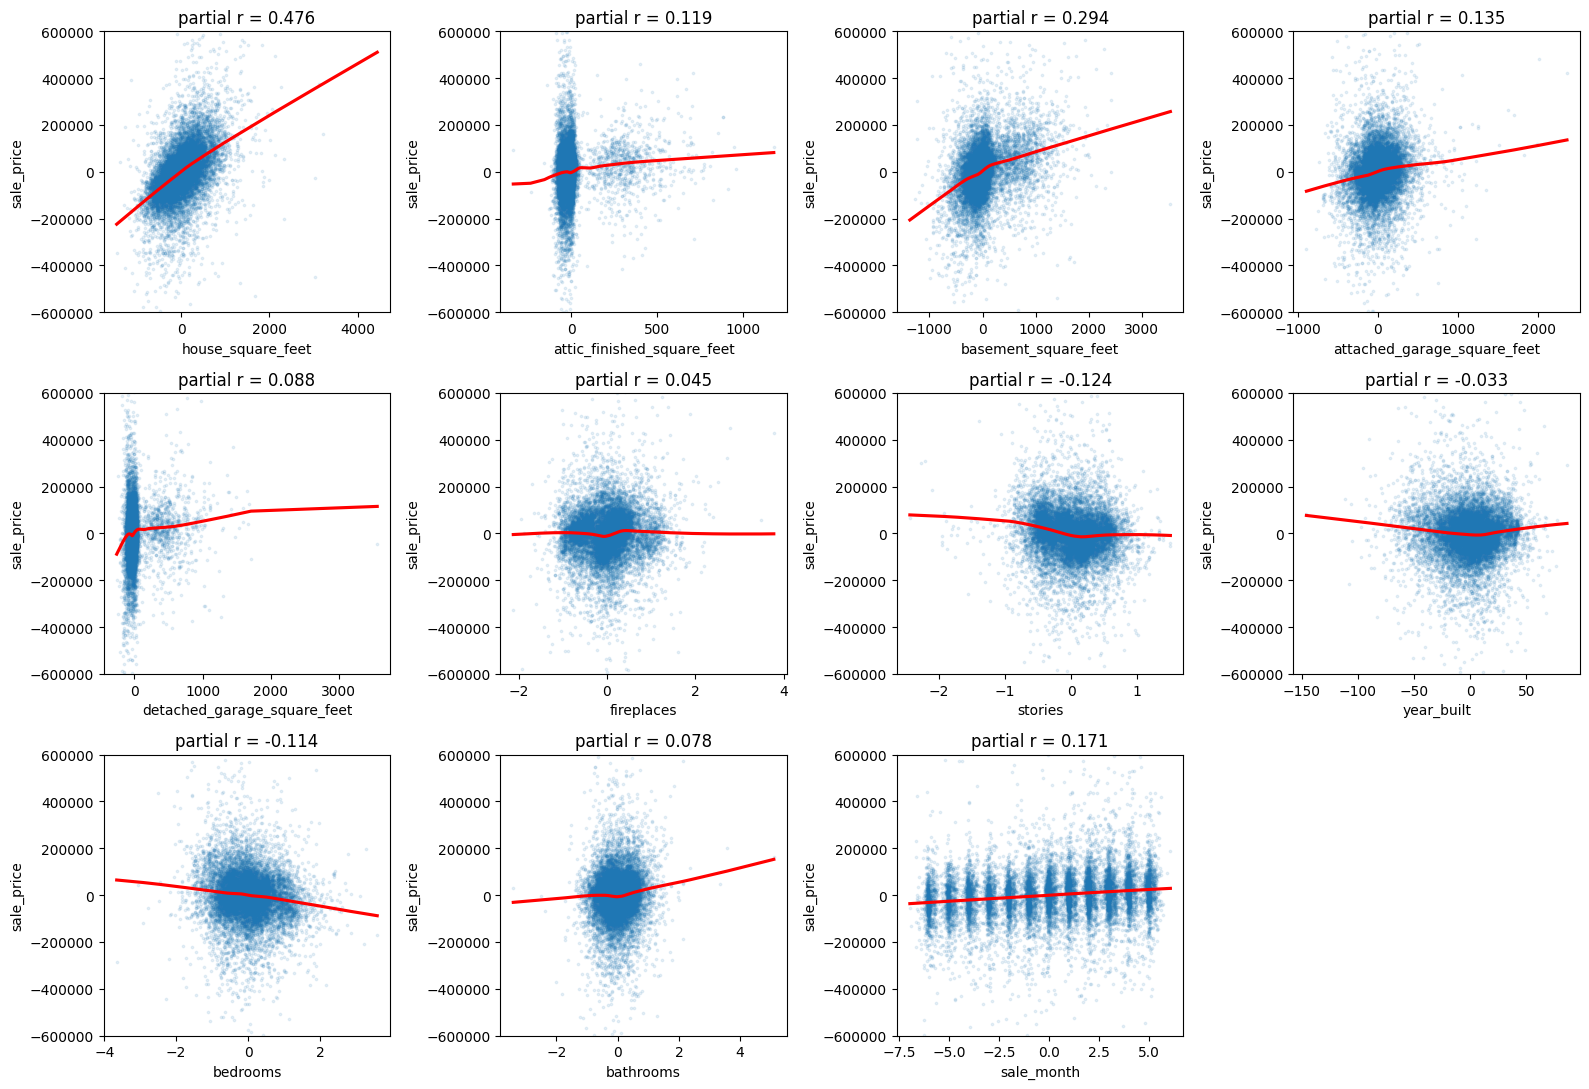

In [ ]:
#Question 5: Partial Correlation Plots
numeric_features = [
"house_square_feet",
"attic_finished_square_feet",
"basement_square_feet",
"attached_garage_square_feet",
"detached_garage_square_feet",
"fireplaces",
"stories",
"year_built",
"bedrooms",
"bathrooms",
"sale_month"
]

plt.figure(figsize=(16, 11))
for i, var in enumerate(numeric_features):
    others = X_train.drop(columns=var)
    price_left = y_train - LinearRegression().fit(others, y_train).predict(others)
    var_left = X_train[var] - LinearRegression().fit(others, X_train[var]).predict(others)
    plt.subplot(3, 4, i + 1)
    sns.regplot(x=var_left, y=price_left, lowess=True, scatter_kws={"alpha": 0.1, "s": 3}, line_kws={"color": "red"})
    plt.ylim(-600000, 600000)
    plt.xlabel(var)
    plt.ylabel("sale_price")
    plt.title("partial r = " + str(round(np.corrcoef(var_left, price_left)[0, 1], 3)))
plt.tight_layout()
plt.show()

For each numeric variable, the plot takes the linear effect of all the other features in Model 3 out of both sale price and that variable, and the red lowess curve shows any bend.

* house_square_feet: Strong positive relationship with sale price, with a partial correlation of 0.476, and close to linear.
* year_built: The clearest non-linear pattern. The curve is U-shaped, so the oldest and newest houses sell for more than mid-century houses with the same features. This motivates the age squared term in Question 6.
* basement_square_feet and detached_garage_square_feet: The curves climb steeply around zero and more slowly after, so having one adds more than each extra square foot.
* bedrooms vs bathrooms: Holding square footage constant, adding bedrooms lowers price, with a partial correlation of -0.114, since rooms get smaller. Bathrooms work the other way, and the curve bends upward, so extra bathrooms add more at the high end.

In [ ]:
# Question 6: Making a more complex model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Create complex features reflecting ideas from EDA & Question 5
X_train_complex = X_train.copy()
X_test_complex = X_test.copy()

for df_c in [X_train_complex, X_test_complex]:
# Non-linear transformations
    df_c["log_house_sqft"] = np.log(df_c["house_square_feet"])
    df_c["house_age"] = 2020 - df_c["year_built"]
    df_c["house_age_sq"] = df_c["house_age"] ** 2  # Captures vintage U-curve

# Interaction term
    df_c["sqft_x_bathrooms"] = df_c["house_square_feet"] * df_c["bathrooms"]

# house_age replaces year_built, since keeping both would repeat the same information
X_train_complex = X_train_complex.drop(columns="year_built")
X_test_complex = X_test_complex.drop(columns="year_built")

# Fit complex model on log price
model_complex = LinearRegression()
model_complex.fit(X_train_complex, np.log(y_train))

# Predict and turn the predictions back into dollars so they compare with Question 4
complex_train_pred = np.exp(model_complex.predict(X_train_complex))
complex_test_pred = np.exp(model_complex.predict(X_test_complex))

print("Complex Model with Transformations and Interactions:")
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, complex_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, complex_test_pred)))
print("Training R²:", r2_score(y_train, complex_train_pred))
print("Test R²:", r2_score(y_test, complex_test_pred))

Complex Model with Transformations and Interactions:
Training RMSE: 113890.286254418
Test RMSE: 109032.8768585339
Training R²: 0.6886217535079987
Test R²: 0.6637356617789738


The complex model predicts log price and adds log house size, house age with age squared for the U shape in Question 5, and an interaction between house size and bathrooms. We turn the predictions back into dollars so they compare with Question 4. Compared with Model 3, training RMSE falls from \$117,144 to \$113,890 and training R² rises from 0.671 to 0.689. On the test set, RMSE only falls from \$109,345 to \$109,033 and R² only rises from 0.662 to 0.664. The complex model is the best so far, but most of its extra fit stays in the training data.

#Question 7

The house-size-only model underfits. Its R² is about 0.4 on both sets, so size alone misses most of what separates houses. Adding bedrooms and bathrooms helps only a little, while adding all features raises test R² to 0.662. Training and test results stay close for these simple models, so they are not overfitting. The complex model raises training R² from 0.671 to 0.689 but test R² only from 0.662 to 0.664, so the gap between training and test grows, an early sign of overfitting.

For model selection, training fit keeps improving as we add terms, so models have to be compared on data they were not fit on. Because we compared our models on the test set, it worked as validation data. A cleaner way is to choose among models with validation data or cross-validation inside the training set and keep the test set for one final evaluation.

In [ ]:
# Question 8: Lasso
from sklearn.linear_model import LassoCV

# Standardize with the training means and standard deviations so the penalty treats every feature alike
Z_train = (X_train_complex - X_train_complex.mean()) / X_train_complex.std()
Z_test = (X_test_complex - X_train_complex.mean()) / X_train_complex.std()

# Choose the penalty by 5-fold cross-validation on the training data
lasso = LassoCV(cv=5).fit(Z_train, np.log(y_train))
coef = pd.Series(lasso.coef_, index=Z_train.columns)
print("alpha:", lasso.alpha_)
print("Features kept:", (coef != 0).sum(), "of", len(coef))
print("Dropped:", coef[coef == 0].index.tolist())
print(coef.sort_values(key=abs, ascending=False).head(10))

# Predict and turn the predictions back into dollars
lasso_train_pred = np.exp(lasso.predict(Z_train))
lasso_test_pred = np.exp(lasso.predict(Z_test))

print("Lasso Model:")
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, lasso_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, lasso_test_pred)))
print("Training R²:", r2_score(y_train, lasso_train_pred))
print("Test R²:", r2_score(y_test, lasso_test_pred))

alpha: 0.00025493145979121375
Features kept: 44 of 45
Dropped: ['exterior_Masonry Common Brick']
log_house_sqft                 0.128899
house_square_feet              0.106230
basement_square_feet           0.074433
house_age                     -0.068630
house_age_sq                   0.063094
waterfront_type_WF Salt        0.057063
bathrooms                      0.046322
waterfront_type_WF Lake        0.045041
sale_month                     0.043799
attached_garage_square_feet    0.040266
dtype: float64
Lasso Model:
Training RMSE: 113957.80696626529
Test RMSE: 109048.17845731026
Training R²: 0.6882524381992174
Test R²: 0.6636412729453632


We standardize the complex model's features with the training means and standard deviations so the penalty treats them alike, and let LassoCV choose the penalty by 5-fold cross-validation on the training data. The chosen alpha is about 0.00025, so the penalty is very small and the Lasso keeps 44 of the 45 features, dropping only the Masonry Common Brick exterior dummy. The largest standardized coefficients belong to log house size, house size, basement area, house age and age squared, salt water frontage and bathrooms. Its test RMSE is $109,048 and test R² is 0.664, with training R² 0.688, almost the same as the complex model without the penalty, so cross-validation found little to gain from shrinking this model.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

:- **Phase 1 commit SHA ID:** e7abb86a3cdec6911147658990a230e1034e99d0
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]